Spotify Dataset - Machine Learning

Lucas Concha
Natalia Hormazabal
Martin Villarroel

In [29]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import MinMaxScaler



df = pd.read_csv('../data/Spotify_Tracks_Dataset.csv')
print(f"Filas y Columnas iniciales: {df.shape}")
df.head()

Filas y Columnas iniciales: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Inspección


In [30]:
df.info()
df.isna().sum()[df.isna().sum() > 0]

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

artists       1
album_name    1
track_name    1
dtype: int64

## Eliminación de variables no predictivas 


In [31]:
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df.shape

(114000, 20)

## Valores nulos


In [32]:
df = df.dropna(subset=["artists", "album_name", "track_name"])
df.shape

(113999, 20)

## Duplicados 

In [33]:
print("Duplicados exactos:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape tras eliminar duplicados exactos:", df.shape)

Duplicados exactos: 450
Shape tras eliminar duplicados exactos: (113549, 20)


In [34]:
rep = df["track_id"].duplicated(keep=False).sum()
print(f"Filas con track_id repetido en distintos generos: {rep} ({rep/len(df)*100:.1f}%)")


Filas con track_id repetido en distintos generos: 40108 (35.3%)


## Outliers

In [35]:
print("Canciones con duration_ms == 0:", (df["duration_ms"] == 0).sum())
print("Canciones con tempo == 0:", (df["tempo"] == 0).sum())

Canciones con duration_ms == 0: 0
Canciones con tempo == 0: 157


In [ ]:
q1, q3 = df["duration_ms"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 3 * iqr
extreme = df[df["duration_ms"] > upper]
print(f"Umbral outlier extremo (Q3 + 3*IQR): {upper/60000:.1f} min")
print(f"Canciones sobre el umbral: {len(extreme)} ({len(extreme)/len(df)*100:.2f}%)")

tempo_zero = df[df["tempo"] == 0].copy()
tempo_zero["anomalia"] = "tempo_cero"
dur_extreme = extreme.copy()
dur_extreme["anomalia"] = "duracion_extrema"
anomalias = pd.concat([tempo_zero, dur_extreme]).drop_duplicates(subset=["track_id", "anomalia"])
anomalias.to_csv("../data_procesado/spotify_tracks_anomalias.csv", index=False)
print("Anomalias exportadas:", anomalias.shape)


## Variables categóricas 

- explicit se convierte a entero 
- Track_genre one hot encoding (para modelar)
- key, mode, time_signature se mantienen como enteros 


In [ ]:
df["explicit"] = df["explicit"].astype(int)

genre_dummies = pd.get_dummies(df["track_genre"], prefix="genre", drop_first=True).astype(int)
df = pd.concat([df.drop(columns=["track_genre"]), genre_dummies], axis=1)
print("Dummies de genero generadas:", genre_dummies.shape[1])
df.head()


## Escalado

In [ ]:
audio_cols = ["danceability", "energy", "loudness", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

scaler = MinMaxScaler()
df[audio_cols] = scaler.fit_transform(df[audio_cols])
df[audio_cols].describe().loc[["min", "max"]]


In [ ]:
df.to_csv("../data_procesado/spotify_tracks_clean.csv", index=False)
print("Shape final exportado:", df.shape)


## Visualizaciones

FileNotFoundError: [Errno 2] No such file or directory: '../images/distribucion_popularity.png'

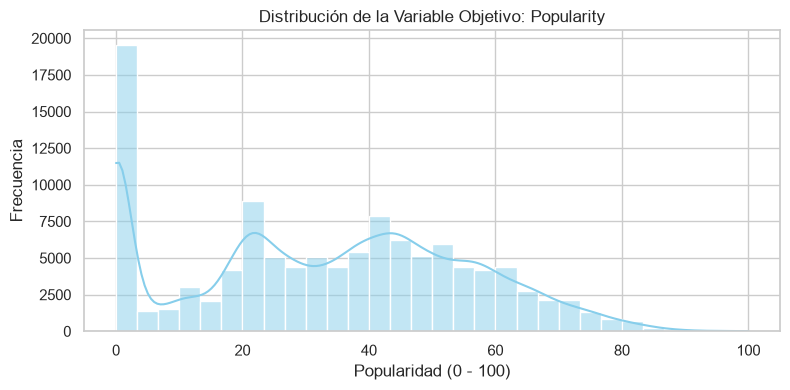

In [40]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# 1. Distribución de la variable objetivo (Popularity)
plt.figure(figsize=(8, 4))
sns.histplot(df['popularity'], kde=True, bins=30, color='skyblue')
plt.title('Distribución de la Variable Objetivo: Popularity')
plt.xlabel('Popularidad (0 - 100)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('../images/distribucion_popularity.png')
plt.show()

# 2. Matriz de Correlación entre características de Audio y Popularity
audio_cols = ["danceability", "energy", "loudness", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo", "popularity"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[audio_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Pearson (Features vs Popularity)')
plt.tight_layout()
plt.savefig('../images/matriz_correlacion.png')
plt.show()

# 3. Boxplot de Detección de Outliers en Duration (Minutos)
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['duration_ms'] / 60000, color='salmon')
plt.title('Detección de Outliers: Duración de Canciones (Minutos)')
plt.xlabel('Duración (Minutos)')
plt.tight_layout()
plt.savefig('../images/boxplot_duration.png')
plt.show()